# BI drivers: where, when and under which conditions disruption happens

Five figures built from `data/processed/airport_day.csv`:

1. Airport performance: traffic, delay per 1,000 arrivals and disruption rate
2. Delay intensity by airport and year
3. Share of ATFM delay by cause and airport (causes outside the six named ones are grouped as Other)
4. Disruption risk ratio by weather condition and airport: disruption rate on days with the condition divided by the rate on days without it. Every cell is shown, as in the original analysis; a second table prints how many disrupted days each ratio rests on.
5. Disruption rate by traffic pressure (relative to the airport's median over 2014 to 2025) and number of adverse weather conditions

A disrupted day is a day on which at least 2% of arrivals had more than 15 minutes of ATFM delay. As in the original analysis, a missing weather reading counts as the condition not occurring (figures 4 and 5).


In [1]:
# ============================================================
# 0. IMPORT LIBRARIES AND LOAD DATA
# ============================================================
# Load the same airport-day table as notebook 01 and print a few sanity checks.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv("../data/processed/airport_day.csv", low_memory=False)

# Convert date to datetime
df["date"] = pd.to_datetime(df["date"])

# Check basic information
print("Shape:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Number of airports:", df["airport_icao"].nunique())
# ============================================================
# CREATE WEATHER EVENT INDICATORS
# ============================================================
# Yes/no weather flags per airport-day, and a mask of days with all five weather
# readings, used later to leave out days with missing weather.

# Weather column behind each weather condition
weather_sources = {
    "Thunderstorm": "thunder_hours",
    "Low visibility": "low_vis_hours_lt1000",
    "Strong gust": "gust_hours_ge15",
    "Snow": "snow_hours",
    "Freezing": "freezing_hours"
}

# True means that this weather condition occurred
# at least once during the airport-day.
for event, column in weather_sources.items():
    df[event] = df[column] > 0

# Days without a weather reading would otherwise count as
# "no event", so the comparisons below leave them out.
weather_observed = (
    df[list(weather_sources.values())]
    .notna()
    .all(axis=1)
)

print(
    "Airport-days missing at least one weather reading:",
    (~weather_observed).sum()
)

Shape: (52596, 79)
Date range: 2014-01-01 00:00:00 to 2025-12-31 00:00:00
Number of airports: 12
Airport-days missing at least one weather reading: 1067


In [2]:
# ============================================================
# FIGURE 1
# AIRPORT PERFORMANCE BUBBLE CHART
# ============================================================
# One summary row per airport: traffic, delay intensity (ratio of sums),
# disruption rate and the weather share of delay, used for the bubble chart.

airport_summary = (
    df.groupby(["airport_icao", "airport_name"])
      .agg(
          total_arrivals=("arrivals", "sum"),
          total_delay=("atfm_delay_min", "sum"),
          # mean of the 0/1 flag = share of disrupted days
          disruption_rate=("disrupted_day", "mean"),
          weather_delay=("delay_weather_min", "sum")
      )
      .reset_index()
)

# Normalized delay intensity
airport_summary["delay_per_1000"] = (
    airport_summary["total_delay"]
    / airport_summary["total_arrivals"]
    * 1000
)

# Percentage of total ATFM delay attributed to weather
airport_summary["weather_delay_share"] = (
    airport_summary["weather_delay"]
    / airport_summary["total_delay"]
    * 100
)

print(
    airport_summary.sort_values(
        "delay_per_1000",
        ascending=False
    )
)

   airport_icao         airport_name  total_arrivals  total_delay  \
1          EDDF            Frankfurt       2544929.0    2264711.0   
4          EDDK         Cologne-Bonn        722317.0     333225.0   
5          EDDL          Duesseldorf       1034925.0     386093.0   
6          EDDM               Munich       1952713.0     692344.0   
8          EDDP        Leipzig-Halle        418220.0     117345.0   
3          EDDH              Hamburg        743571.0     205862.0   
9          EDDS            Stuttgart        584407.0      71024.0   
11         EDDW               Bremen        156813.0      12470.0   
10         EDDV             Hannover        317643.0       5957.0   
0          EDDC              Dresden         99441.0        661.0   
7          EDDN            Nuremberg        253542.0       1090.0   
2          EDDG  Muenster-Osnabrueck        105906.0         61.0   

    disruption_rate  weather_delay  delay_per_1000  weather_delay_share  
1          0.193931      172

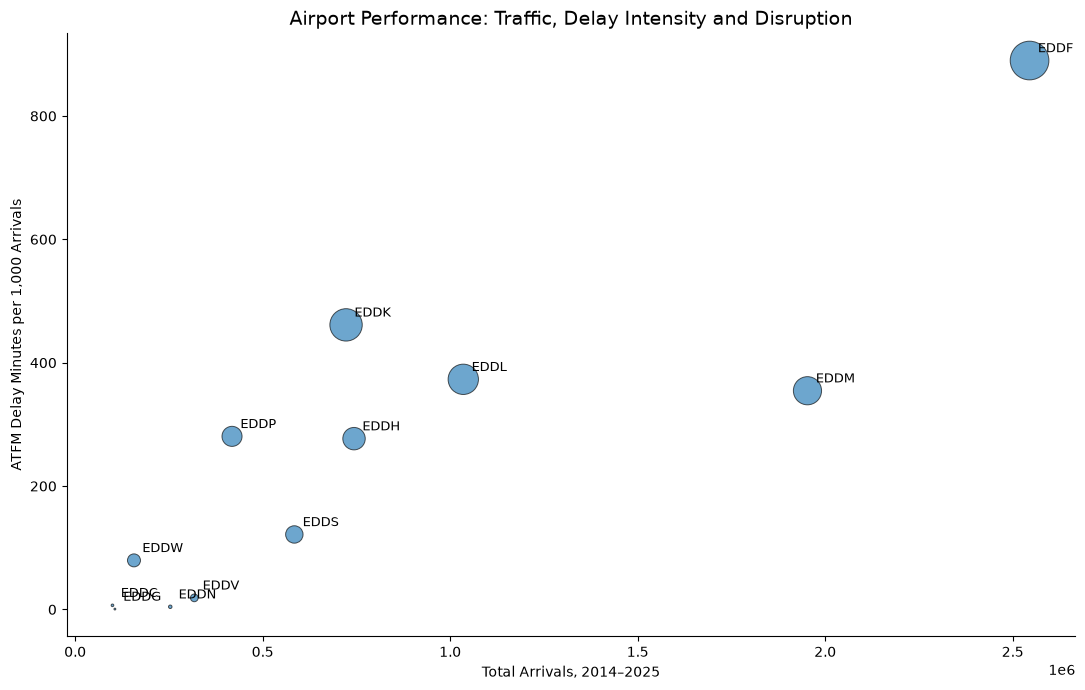

In [3]:
# Bubble chart: x = total arrivals, y = delay per 1,000 arrivals, bubble size =
# disruption rate. Shows whether the busiest airports are also the most delayed.
fig, ax = plt.subplots(figsize=(11, 7))

# Bubble size represents disruption rate.
# Multiplying by 4000 only makes the bubbles large enough to see.
bubble_size = (
    airport_summary["disruption_rate"] * 4000
)

scatter = ax.scatter(
    airport_summary["total_arrivals"],
    airport_summary["delay_per_1000"],
    s=bubble_size,
    alpha=0.65,
    edgecolors="black",
    linewidth=0.7
)

# Add airport ICAO labels
for _, row in airport_summary.iterrows():
    
    ax.annotate(
        row["airport_icao"],
        (
            row["total_arrivals"],
            row["delay_per_1000"]
        ),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9
    )

ax.set_title(
    "Airport Performance: Traffic, Delay Intensity and Disruption",
    fontsize=14
)

ax.set_xlabel(
    "Total Arrivals, 2014–2025"
)

ax.set_ylabel(
    "ATFM Delay Minutes per 1,000 Arrivals"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

year                   2014   2015   2016    2017   2018   2019   2020   2021  \
airport_name                                                                    
Bremen                  1.0    1.0   33.0     6.0  413.0  336.0    9.0   24.0   
Cologne-Bonn           20.0   19.0   80.0   389.0  472.0  314.0   34.0  799.0   
Dresden                 0.0    0.0   12.0     2.0    0.0    0.0    0.0    3.0   
Duesseldorf           388.0  343.0  547.0   718.0  449.0  682.0  265.0   27.0   
Frankfurt            1296.0  674.0  869.0  1026.0  908.0  872.0  187.0  193.0   
Hamburg               279.0  571.0  390.0   258.0  550.0  558.0   31.0   24.0   
Hannover                0.0    0.0    0.0     0.0   34.0    1.0    0.0   71.0   
Leipzig-Halle           0.0    0.0  183.0   124.0  346.0  351.0  141.0  306.0   
Muenster-Osnabrueck     3.0    0.0    0.0     0.0    0.0    0.0    0.0    0.0   
Munich                511.0  332.0  489.0   354.0  438.0  251.0   79.0  130.0   
Nuremberg              16.0 

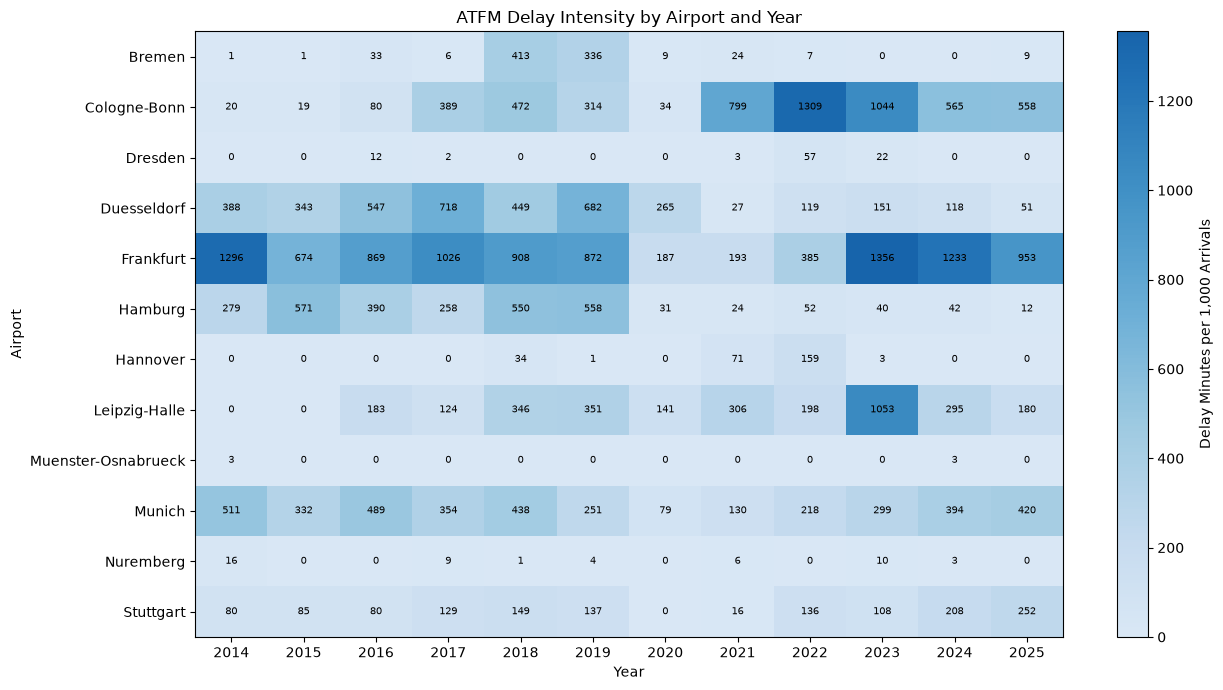

In [4]:
# ============================================================
# FIGURE 2
# AIRPORT × YEAR DELAY HEATMAP
# ============================================================
# Delay per 1,000 arrivals for every airport and year, computed from yearly sums
# and pivoted into an airport x year matrix for the heatmap.

airport_year = (
    df.groupby(["airport_name", "year"])
      .agg(
          arrivals=("arrivals", "sum"),
          delay=("atfm_delay_min", "sum")
      )
      .reset_index()
)

airport_year["delay_per_1000"] = (
    airport_year["delay"]
    / airport_year["arrivals"]
    * 1000
)
delay_matrix = (
    airport_year
    .pivot(
        index="airport_name",
        columns="year",
        values="delay_per_1000"
    )
)

print(delay_matrix.round(0))

from matplotlib import colormaps
from matplotlib.colors import LinearSegmentedColormap

base_cmap = colormaps["Blues"]

# Only the 15%-80% part of the Blues map, so low cells are not white and high
# cells are not too dark for the black value labels
light_blues = LinearSegmentedColormap.from_list(
    "light_blues",
    base_cmap(np.linspace(0.15, 0.8, 256))
)
fig, ax = plt.subplots(figsize=(13, 7))

image = ax.imshow(
    delay_matrix.values,
    aspect="auto",
    cmap=light_blues
)
ax.set_xticks(
    np.arange(len(delay_matrix.columns))
)

ax.set_xticklabels(
    delay_matrix.columns
)

ax.set_yticks(
    np.arange(len(delay_matrix.index))
)

ax.set_yticklabels(
    delay_matrix.index
)

# Add values inside cells
for i in range(len(delay_matrix.index)):
    for j in range(len(delay_matrix.columns)):
        
        value = delay_matrix.iloc[i, j]
        
        # Skip airport-years without a value
        if pd.notna(value):
            ax.text(
                j,
                i,
                f"{value:.0f}",
                ha="center",
                va="center",
                fontsize=7
            )

cbar = fig.colorbar(image, ax=ax)

cbar.set_label(
    "Delay Minutes per 1,000 Arrivals"
)

ax.set_title(
    "ATFM Delay Intensity by Airport and Year"
)

ax.set_xlabel("Year")
ax.set_ylabel("Airport")

plt.tight_layout()
plt.show()

                     Weather  Aerodrome\ncapacity  ATC\ncapacity  \
Airport                                                            
Bremen                   0.5                  2.1            0.1   
Cologne-Bonn            19.0                 73.9            1.6   
Dresden                  0.0                  0.0            0.0   
Duesseldorf             35.7                 26.7            1.5   
Frankfurt               76.0                 10.6            0.9   
Hamburg                 27.4                 54.7            1.4   
Hannover                 0.7                 28.4           59.3   
Leipzig-Halle           73.4                  7.3            1.7   
Muenster-Osnabrueck      0.0                  0.0            0.0   
Munich                  93.7                  2.2            1.6   
Nuremberg                0.0                 31.8           15.1   
Stuttgart               58.6                  0.6           15.8   

                     ATC\nstaffing  ATC\nroutin

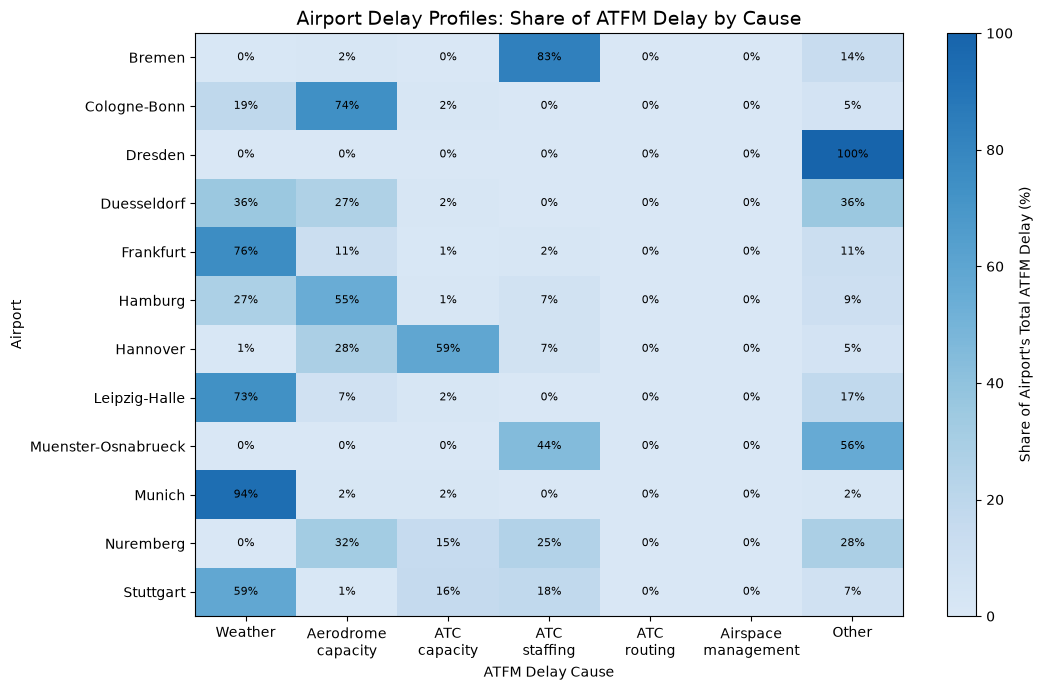

In [5]:
# ============================================================
# FIGURE 3
# DELAY CAUSE × AIRPORT HEATMAP
# ============================================================
# For each airport, the percentage of its own total ATFM delay assigned to each
# cause. Shares are within an airport, so airports of different size compare.

delay_causes = {
    "Weather": "delay_weather_min",
    "Aerodrome\ncapacity": "delay_aerodrome_capacity_min",
    "ATC\ncapacity": "delay_atc_capacity_min",
    "ATC\nstaffing": "delay_atc_staffing_min",
    "ATC\nrouting": "delay_atc_routeing_min",
    "Airspace\nmanagement": "delay_airspace_mgmt_min"
}
cause_data = []

for airport, group in df.groupby("airport_name"):
    
    total_delay = group["atfm_delay_min"].sum()
    
    row = {
        "Airport": airport
    }
    
    for cause_name, column in delay_causes.items():
        
        cause_delay = group[column].sum()
        
        # Avoid dividing by zero for an airport with no delay
        if total_delay > 0:
            share = cause_delay / total_delay * 100
        else:
            share = 0
        
        row[cause_name] = share
    
    # Everything outside the six named causes
    if total_delay > 0:
        row["Other"] = 100 - sum(
            row[cause_name] for cause_name in delay_causes
        )
    else:
        row["Other"] = 0
    
    cause_data.append(row)

cause_df = pd.DataFrame(cause_data)

cause_matrix = (
    cause_df
    .set_index("Airport")
)

print(cause_matrix.round(1))

from matplotlib import colormaps
from matplotlib.colors import LinearSegmentedColormap

base_cmap = colormaps["Blues"]

# Lighter part of the Blues map so the black labels stay readable
light_blues = LinearSegmentedColormap.from_list(
    "light_blues",
    base_cmap(np.linspace(0.15, 0.8, 256))
)
fig, ax = plt.subplots(figsize=(11, 7))

image = ax.imshow(
    cause_matrix.values,
    aspect="auto",
    cmap=light_blues
)

ax.set_xticks(
    np.arange(len(cause_matrix.columns))
)

ax.set_xticklabels(
    cause_matrix.columns
)

ax.set_yticks(
    np.arange(len(cause_matrix.index))
)

ax.set_yticklabels(
    cause_matrix.index
)

# Put percentages inside cells
for i in range(len(cause_matrix.index)):
    for j in range(len(cause_matrix.columns)):
        
        value = cause_matrix.iloc[i, j]
        
        ax.text(
            j,
            i,
            f"{value:.0f}%",
            ha="center",
            va="center",
            fontsize=8
        )

cbar = fig.colorbar(
    image,
    ax=ax
)

cbar.set_label(
    "Share of Airport's Total ATFM Delay (%)"
)

ax.set_title(
    "Airport Delay Profiles: Share of ATFM Delay by Cause",
    fontsize=14
)

ax.set_xlabel("ATFM Delay Cause")
ax.set_ylabel("Airport")

plt.tight_layout()
plt.show()

Weather              Freezing  Low visibility   Snow  Strong gust  \
Airport                                                             
Bremen                   2.10            1.28   1.53         1.02   
Cologne-Bonn             1.18            1.99   0.68         1.25   
Dresden                  0.00            0.00   2.98         0.00   
Duesseldorf              1.57            1.28   0.79         1.18   
Frankfurt                2.24            3.53   1.21         1.83   
Hamburg                  0.35            1.91   1.25         1.35   
Hannover                 0.00            1.59   0.49         1.24   
Leipzig-Halle            2.52            3.07   2.12         3.11   
Muenster-Osnabrueck      0.00            0.00  18.17         0.00   
Munich                   2.22            2.30   1.30         1.41   
Nuremberg                0.00            0.00   0.00         0.00   
Stuttgart                1.70            2.18   0.34         2.13   

Weather              Thunderstorm

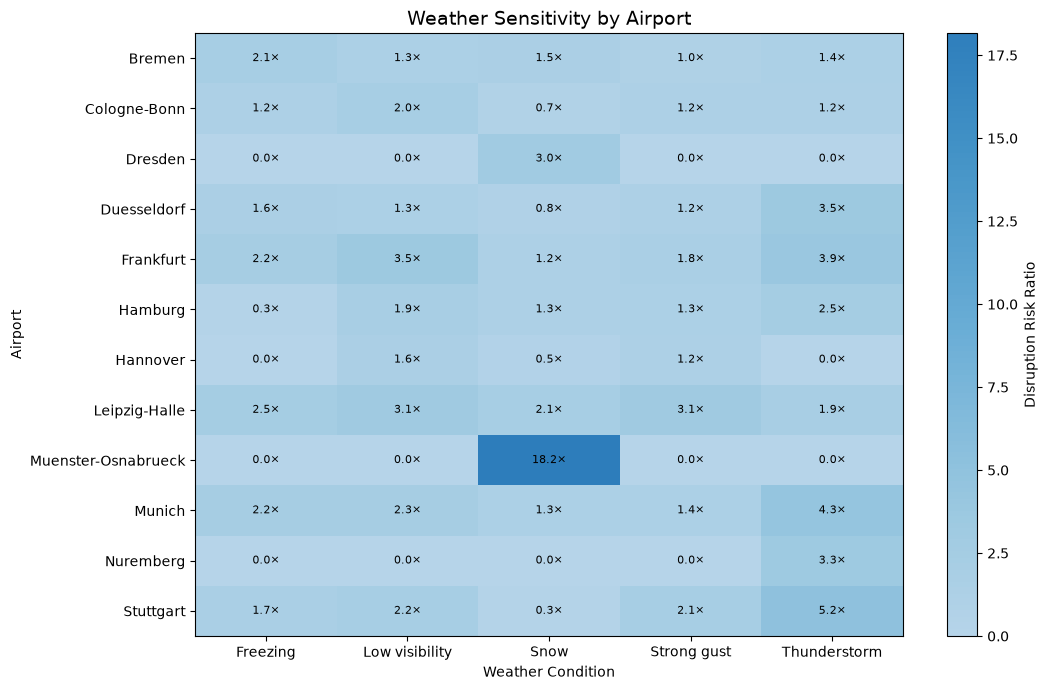

In [6]:
# The five weather flags created in the first cell, looped over below.
weather_events = [
    "Thunderstorm",
    "Low visibility",
    "Strong gust",
    "Snow",
    "Freezing"
]
# ============================================================
# FIGURE 4
# WEATHER × AIRPORT RISK MATRIX
# ============================================================
# Risk ratio per airport and weather condition = disruption rate on days with the
# condition / rate on days without it (1.0 means no difference).

# Every cell is shown, as in the original analysis; the second printed table
# gives the number of disrupted days behind each ratio, so small ones can be spotted.

weather_risk_data = []

for airport, group in df.groupby("airport_name"):
    
    for weather in weather_events:
        
        # All days of the airport; a missing reading counts as the condition not occurring
        observed = group
        
        # Disrupted days when weather condition is present
        disrupted_with_weather = observed.loc[
            observed[weather],
            "disrupted_day"
        ].sum()
        
        # Disruption rate when weather condition is present
        with_weather = observed.loc[
            observed[weather],
            "disrupted_day"
        ].mean()
        
        # Disruption rate when weather condition is absent
        without_weather = observed.loc[
            ~observed[weather],
            "disrupted_day"
        ].mean()
        
        # Risk ratio, undefined only if the airport never had (or always had) the condition
        if (
            pd.notna(with_weather)
            and pd.notna(without_weather)
            and without_weather > 0
        ):
            risk_ratio = (
                with_weather / without_weather
            )
        else:
            risk_ratio = np.nan
        
        weather_risk_data.append({
            "Airport": airport,
            "Weather": weather,
            "Risk Ratio": risk_ratio,
            "Disrupted days": disrupted_with_weather
        })

weather_risk_df = pd.DataFrame(
    weather_risk_data
)

weather_risk_matrix = (
    weather_risk_df
    .pivot(
        index="Airport",
        columns="Weather",
        values="Risk Ratio"
    )
)

print(
    weather_risk_matrix.round(2)
)

# Disrupted days behind each cell
print(
    weather_risk_df
    .pivot(
        index="Airport",
        columns="Weather",
        values="Disrupted days"
    )
    .astype(int)
)

from matplotlib import colormaps
from matplotlib.colors import LinearSegmentedColormap

base_cmap = colormaps["Blues"]

light_blues = LinearSegmentedColormap.from_list(
    "light_blues",
    base_cmap(np.linspace(0.3, 0.7, 256))
)

# Blank (masked) cells are shown in light grey
light_blues.set_bad("#eeeeee")
fig, ax = plt.subplots(figsize=(11, 7))
image = ax.imshow(
    # Mask the NaN cells so imshow draws them in the 'bad' colour set above
    np.ma.masked_invalid(weather_risk_matrix.values),
    aspect="auto",
    cmap=light_blues
)

ax.set_xticks(
    np.arange(
        len(weather_risk_matrix.columns)
    )
)

ax.set_xticklabels(
    weather_risk_matrix.columns
)

ax.set_yticks(
    np.arange(
        len(weather_risk_matrix.index)
    )
)

ax.set_yticklabels(
    weather_risk_matrix.index
)

# Write risk ratios into cells
for i in range(
    len(weather_risk_matrix.index)
):
    
    for j in range(
        len(weather_risk_matrix.columns)
    ):
        
        value = (
            weather_risk_matrix.iloc[i, j]
        )
        
        if pd.notna(value):
            
            ax.text(
                j,
                i,
                f"{value:.1f}×",
                ha="center",
                va="center",
                fontsize=8
            )
        
        else:
            
            ax.text(
                j,
                i,
                "n/a",
                ha="center",
                va="center",
                fontsize=7,
                color="grey"
            )

cbar = fig.colorbar(
    image,
    ax=ax
)

cbar.set_label(
    "Disruption Risk Ratio"
)

ax.set_title(
    "Weather Sensitivity by Airport",
    fontsize=14
)

ax.set_xlabel(
    "Weather Condition"
)

ax.set_ylabel(
    "Airport"
)

plt.tight_layout()
plt.show()

traffic_group         Low (<80%)  Normal (80–100%)  High (100–120%)  \
weather_hazard_group                                                  
No hazard                    0.5               3.7              6.0   
1 hazard                     1.6               8.8             15.3   
2 hazards                    4.0              16.2             25.7   
3+ hazards                  13.3              22.5             12.8   

traffic_group         Very high (>120%)  
weather_hazard_group                     
No hazard                           8.5  
1 hazard                           13.3  
2 hazards                          18.0  
3+ hazards                          7.7  


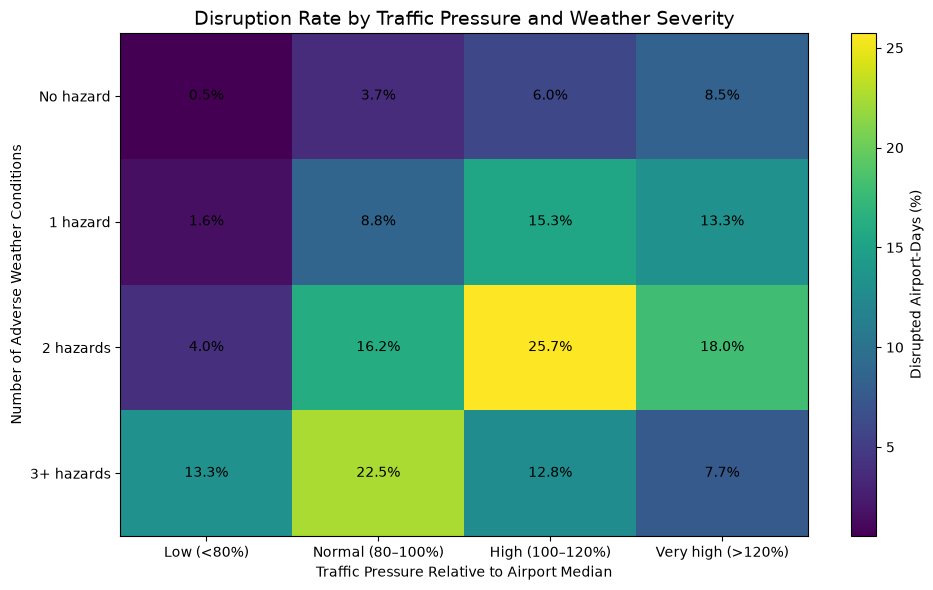

In [7]:
# ============================================================
# FIGURE 5
# TRAFFIC × WEATHER × DISRUPTION HEATMAP
# ============================================================
# Disruption rate by traffic pressure (arrivals / airport's median over 2014-2025)
# and by how many of the five weather conditions occurred that day.

# One median per airport over all years, as in the original analysis.
# Traffic was much lower in 2020-2021, so those days fall mostly in "Low".
# transform() returns each row's group median, aligned with df
airport_median_arrivals = (
    df.groupby("airport_icao")["arrivals"]
      .transform("median")
)

df["traffic_pressure"] = (
    df["arrivals"]
    / airport_median_arrivals
)

df["traffic_group"] = pd.cut(
    df["traffic_pressure"],
    bins=[
        -np.inf,
        0.8,
        1.0,
        1.2,
        np.inf
    ],
    labels=[
        "Low (<80%)",
        "Normal (80–100%)",
        "High (100–120%)",
        "Very high (>120%)"
    ]
)

weather_columns = [
    "Thunderstorm",
    "Low visibility",
    "Strong gust",
    "Snow",
    "Freezing"
]

# Number of the five conditions that occurred; a missing reading counts as
# not occurred, as in the original analysis
df["weather_hazard_count"] = (
    df[weather_columns]
    .sum(axis=1)
)

# Bins (-1, 0], (0, 1], (1, 2], (2, inf) give the groups 0, 1, 2 and 3+ hazards
df["weather_hazard_group"] = pd.cut(
    df["weather_hazard_count"],
    bins=[
        -1,
        0,
        1,
        2,
        np.inf
    ],
    labels=[
        "No hazard",
        "1 hazard",
        "2 hazards",
        "3+ hazards"
    ]
)

traffic_weather = (
    df.groupby(
        [
            "weather_hazard_group",
            "traffic_group"
        ],
        observed=True
    )
    ["disrupted_day"]
    .mean()
    .unstack()
    * 100
)

print(
    traffic_weather.round(1)
)

fig, ax = plt.subplots(figsize=(10, 6))

# Default colour map (viridis): brighter cells have higher disruption rates
image = ax.imshow(
    traffic_weather.values,
    aspect="auto"
)

# X-axis: traffic pressure
ax.set_xticks(
    np.arange(
        len(traffic_weather.columns)
    )
)

ax.set_xticklabels(
    traffic_weather.columns
)

# Y-axis: weather severity
ax.set_yticks(
    np.arange(
        len(traffic_weather.index)
    )
)

ax.set_yticklabels(
    traffic_weather.index
)

# Add disruption percentages inside cells
for i in range(
    len(traffic_weather.index)
):
    
    for j in range(
        len(traffic_weather.columns)
    ):
        
        value = (
            traffic_weather.iloc[i, j]
        )
        
        if pd.notna(value):
            
            ax.text(
                j,
                i,
                f"{value:.1f}%",
                ha="center",
                va="center",
                fontsize=10
            )

cbar = fig.colorbar(
    image,
    ax=ax
)

cbar.set_label(
    "Disrupted Airport-Days (%)"
)

ax.set_title(
    "Disruption Rate by Traffic Pressure and Weather Severity",
    fontsize=14
)

ax.set_xlabel(
    "Traffic Pressure Relative to Airport Median"
)

ax.set_ylabel(
    "Number of Adverse Weather Conditions"
)

plt.tight_layout()
plt.show()